# exp13: Sequence Sensor

Menguji GRU kecil dari urutan sensor kausal sampai tujuh endpoint. MLP statis dan history generik menjadi pembanding pada fitur inti yang sama.


## Lokasi proyek

Input dibaca dari Google Drive, termasuk pintasan folder bersama. Training menulis file kerja ke disk sementara Colab; checkpoint dan hasil disimpan otomatis ke Drive. Tidak ada upload CSV melalui notebook.


In [1]:
from pathlib import Path
import os
import sys
from google.colab import drive

drive.mount('/content/drive')
IN_COLAB = True
PROJECT_ROOT = Path('/content/drive/MyDrive/Penelitian-Adaptive-IDE')
BATCH_DIR = PROJECT_ROOT / 'models' / 'batch-02'
if not (BATCH_DIR / 'shared' / 'batch02').is_dir():
    raise FileNotFoundError('Salin folder batch-02, termasuk shared, requirements.txt, dan sensor_streams ke Drive.')
sys.path.insert(0, str(BATCH_DIR / 'shared'))
from colab_bootstrap import prepare_workspace
WORK_BATCH_DIR = prepare_workspace(BATCH_DIR)
if 'batch02' in sys.modules and Path(sys.modules['batch02'].__file__).resolve().parent != WORK_BATCH_DIR / 'shared' / 'batch02':
    raise RuntimeError('Restart runtime sebelum memakai paket workspace terbaru, lalu jalankan dari awal.')
sys.path.insert(0, str(WORK_BATCH_DIR / 'shared'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Environment

Dependency inti diperiksa dan dipasang bila diperlukan. Dependency neural juga diperiksa; CUDA digunakan jika tersedia. Jika diminta restart runtime setelah instalasi, restart sekali lalu jalankan dari awal. TabPFN tetap opsional dan tidak mengunduh checkpoint otomatis.


In [2]:
from batch02.runtime import ensure_environment

# Gunakan runtime Colab 2026.10 (Python 3.13) atau runtime Python >=3.12.
ENABLE_TABPFN = False
INSTALL_DEPENDENCIES = True
OPTIONAL_GROUPS = ('neural',)
environment_status = ensure_environment(WORK_BATCH_DIR, install=INSTALL_DEPENDENCIES, optional=OPTIONAL_GROUPS)
print(environment_status)
if environment_status['status'] not in ('ready', 'installed'):
    raise RuntimeError('Dependency belum sesuai. Periksa hasil cell Environment.')


{'status': 'ready', 'missing': [], 'python': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]'}


## Konfigurasi

Ketiga panjang window diproses oleh notebook yang sama. `RESUME_DIR = None` membuat run baru. Untuk resume, isi path folder run di Drive; checkpoint valid dipulihkan ke workspace. Data, kode, konfigurasi, dan environment harus tetap kompatibel.


In [3]:
from batch02.contracts import Config

EXPERIMENT = 'exp13'
DATASET_ROOT = PROJECT_ROOT / 'Dataset' / 'v2_session_phase'
RESUME_DIR = None
CPU_THREADS = max(1, min(4, os.cpu_count() or 1))
config = Config(PROJECT_ROOT, dataset_root=DATASET_ROOT, batch_root=WORK_BATCH_DIR, threads=CPU_THREADS)
from batch02.persistence import RunPersistence
persistence = RunPersistence(WORK_BATCH_DIR, BATCH_DIR, EXPERIMENT)
print('Dataset Drive:', config.dataset)
print('Workspace sementara:', config.batch)
print('Output Drive:', BATCH_DIR / 'outputs' / EXPERIMENT)
print('CPU threads:', CPU_THREADS)


Dataset Drive: /content/drive/.shortcut-targets-by-id/1UUN1XmTGZ26yyLZDlQJn_pKn7-zFwLGg/Penelitian-Adaptive-IDE/Dataset/v2_session_phase
Workspace sementara: /content/batch02-work/5cbfc8880194ad4cdd99
Output Drive: /content/drive/MyDrive/Penelitian-Adaptive-IDE/models/batch-02/outputs/exp13
CPU threads: 2


## Input Release dan Pembagian Data

Memuat snapshot yang sudah disahkan. Training berhenti sebelum fitting jika gate belum lengkap atau hash input berubah. Semua sesi orang yang sama tetap satu grup; identitas hanya mengatur evaluasi.


In [4]:
from batch02.contracts import load_release

release, frames, feature_allowlist, split_manifest = load_release(config)
display(release['summary'])
print('Release:', release['release_id'])
print('Fitur sensor:', len(feature_allowlist))


{'15': {'rows': 3579,
  'classes': {'Medium': 1266, 'High': 1251, 'Low': 1062},
  'groups_metadata': 21},
 '25': {'rows': 3214,
  'classes': {'High': 1137, 'Medium': 1093, 'Low': 984},
  'groups_metadata': 21},
 '45': {'rows': 2527,
  'classes': {'Low': 908, 'High': 891, 'Medium': 728},
  'groups_metadata': 20}}

Release: 5cbfc8880194ad4cdd99
Fitur sensor: 26


## Kandidat dan Rancangan Evaluasi

Menampilkan perlakuan yang akan diuji sebelum training. Pemilihan parameter menggunakan inner validation. Macro-F1 dari pooled outer OOF menjadi metrik utama; accuracy, precision, recall, dan confusion matrix melengkapinya.


In [5]:
from batch02.runner import describe_experiment
from batch02.registry import experiment_windows

candidate_table = describe_experiment(EXPERIMENT)
display(candidate_table)
print('Window:', experiment_windows(EXPERIMENT))


,recipe_id,model,features,baseline_ratio,scaler,missing,normalization,history,selector,balance,indicator,winsor,thin,support,decision,params
0,gru_69f14097d211a68f,gru,F4,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{}
1,mlp_f19a27441aa74e78,mlp,F4,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{}
2,logistic_d1ed61b6e4005640,logistic,F4,False,standard,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
3,logistic_9e9f919bf99207cf,logistic,F4,False,standard,median,N0,15,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
4,logistic_59422ef74f312461,logistic,F4,False,standard,median,N0,30,none,none,False,False,5,native,"(1.0, 1.0, 1.0)",{'C': 1.0}
5,xgboost_2b96aa14445ac291,xgboost,F4,False,none,median,N0,0,none,none,False,False,5,native,"(1.0, 1.0, 1.0)","{'max_depth': 3, 'learning_rate': 0.05, 'min_c..."
6,xgboost_03358625879636a2,xgboost,F4,False,none,median,N0,15,none,none,False,False,5,native,"(1.0, 1.0, 1.0)","{'max_depth': 3, 'learning_rate': 0.05, 'min_c..."
7,xgboost_f29e44541c097745,xgboost,F4,False,none,median,N0,30,none,none,False,False,5,native,"(1.0, 1.0, 1.0)","{'max_depth': 3, 'learning_rate': 0.05, 'min_c..."


Window: (15, 25, 45)


## Training dan Evaluasi

Cell ini menjalankan fitting dan evaluasi penelitian pada snapshot release yang disetujui. Preprocessing, seleksi, balancing, serta stopping mengikuti fitting partition. Hasil disimpan per fold; RESUME_DIR hanya boleh menunjuk run dengan identitas data/kode/environment yang sama.


In [6]:
from batch02.runner import run_experiment

run_dir, results = run_experiment(config, EXPERIMENT, resume=RESUME_DIR, persistence=persistence)
print('Workspace hasil:', run_dir)
print('Hasil permanen Drive:', persistence.remote)
display(results)


Rencana pekerjaan: [{'window_seconds': 15, 'support': 'native', 'status': 'estimated', 'outer_folds': 21, 'candidate_limit_or_count': 8, 'base_inner_fits': 504, 'base_outer_refits': 168, 'ineligible_candidates': [], 'extra_work': 'fusion/binary submodels, neural stopping/refit, paired evaluation, sensitivities, and deployment are additional', 'runtime_estimate_seconds': None, 'runtime_estimate_reason': 'No real-model training benchmark has been run.'}, {'window_seconds': 25, 'support': 'native', 'status': 'estimated', 'outer_folds': 21, 'candidate_limit_or_count': 8, 'base_inner_fits': 504, 'base_outer_refits': 168, 'ineligible_candidates': [], 'extra_work': 'fusion/binary submodels, neural stopping/refit, paired evaluation, sensitivities, and deployment are additional', 'runtime_estimate_seconds': None, 'runtime_estimate_reason': 'No real-model training benchmark has been run.'}, {'window_seconds': 45, 'support': 'native', 'status': 'estimated', 'outer_folds': 20, 'candidate_limit_or_

,window_seconds,comparison,support,rows,complete_oof,macro_f1,accuracy,balanced_accuracy
0,15,gru_69f14097d211a68f,native,3579,True,0.276904,0.313775,0.300583
1,15,logistic_59422ef74f312461,native,3579,True,0.323650,0.335010,0.327582
2,15,logistic_9e9f919bf99207cf,native,3579,True,0.328878,0.340598,0.333300
3,15,logistic_d1ed61b6e4005640,native,3579,True,0.326961,0.341436,0.333597
4,15,mlp_f19a27441aa74e78,native,3579,True,0.289466,0.348421,0.331821
5,15,xgboost_03358625879636a2,native,3579,True,0.311425,0.316848,0.311717
6,15,xgboost_2b96aa14445ac291,native,3579,True,0.307223,0.311819,0.307262
7,15,xgboost_f29e44541c097745,native,3579,True,0.326437,0.330819,0.326399
8,25,gru_69f14097d211a68f,native,3214,True,0.289184,0.299627,0.294227
9,25,logistic_59422ef74f312461,native,3214,True,0.298429,0.304605,0.300307


## Hasil Tersimpan

Ringkasan berikut dibaca dari prediksi yang benar-benar dihasilkan. Cabang skipped tidak diberi skor nol; OOF parsial tidak diperlakukan sebagai evaluasi lengkap. SVM mengekspor decision score, bukan probabilitas.


{'status': 'complete_with_skips',
 'training_performed': True,
 'summary_rows': 24}

,comparison,label,precision,recall,f1,support
0,15/native/gru_69f14097d211a68f,Low,0.160633,0.066855,0.094415,1062
1,15/native/gru_69f14097d211a68f,Medium,0.354875,0.503160,0.416204,1266
2,15/native/gru_69f14097d211a68f,High,0.309240,0.331735,0.320093,1251
3,15/native/logistic_59422ef74f312461,Low,0.251541,0.192090,0.217832,1062
4,15/native/logistic_59422ef74f312461,Medium,0.366790,0.392575,0.379245,1266
...,...,...,...,...,...,...
67,45/native/xgboost_2b96aa14445ac291,Medium,0.312741,0.333791,0.322924,728
68,45/native/xgboost_2b96aa14445ac291,High,0.285285,0.319865,0.301587,891
69,45/native/xgboost_f29e44541c097745,Low,0.308354,0.276432,0.291521,908
70,45/native/xgboost_f29e44541c097745,Medium,0.270161,0.276099,0.273098,728


Confusion matrix deskriptif 15s: logistic_9e9f919bf99207cf. Ranking outer ini tidak dipakai untuk seleksi model akhir.


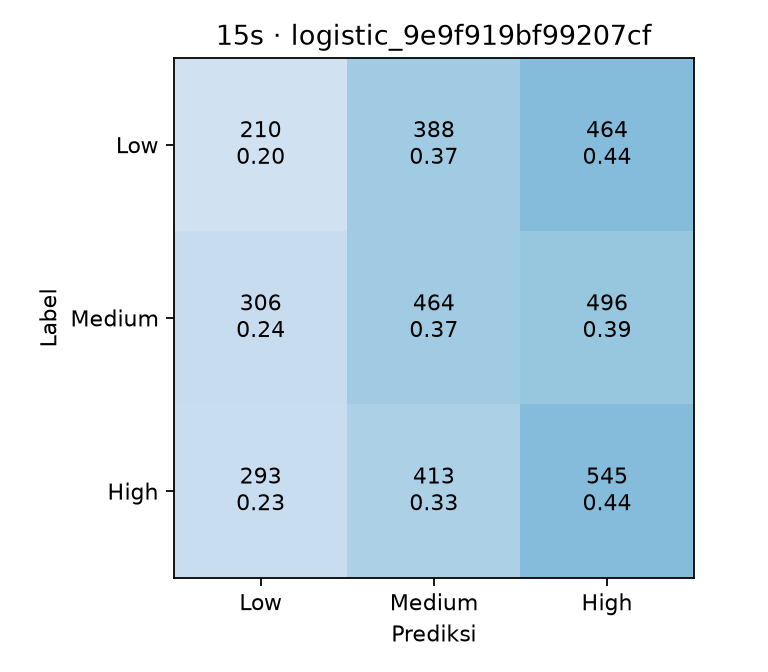

Confusion matrix deskriptif 25s: xgboost_03358625879636a2. Ranking outer ini tidak dipakai untuk seleksi model akhir.


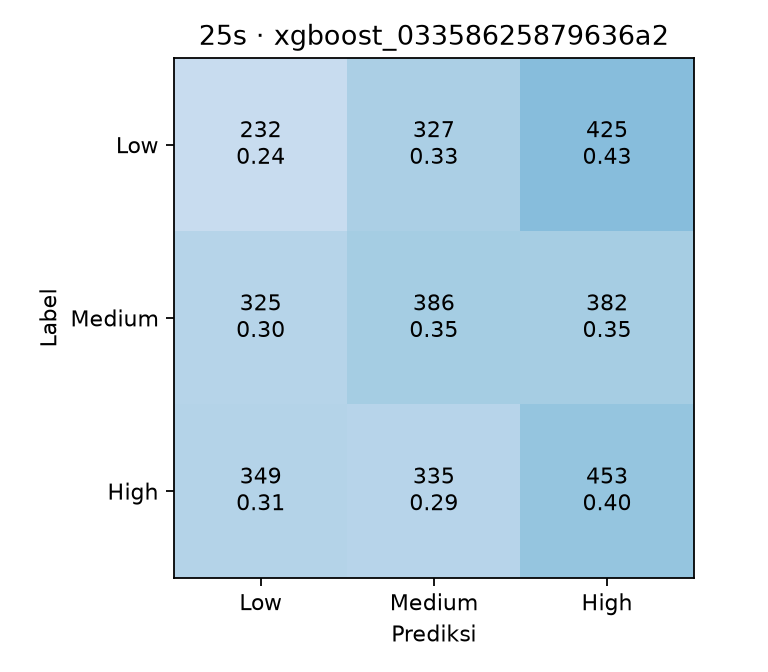

Confusion matrix deskriptif 45s: xgboost_2b96aa14445ac291. Ranking outer ini tidak dipakai untuk seleksi model akhir.


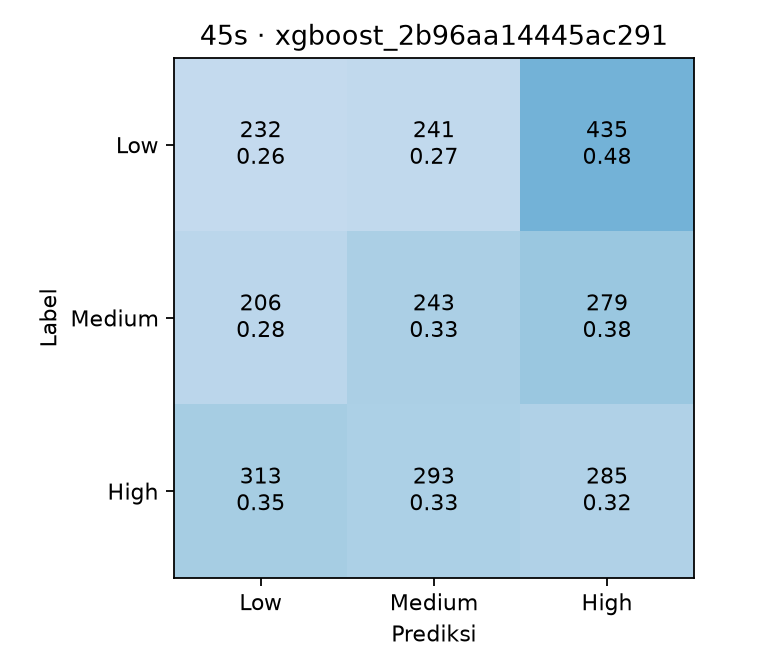

,id,person,status
0,fold_11,Siti,no_test_support


In [7]:
from batch02.reporting import display_notebook_results

display_notebook_results(run_dir)


## Pemulihan Penyimpanan

Jalankan cell berikut hanya jika upload checkpoint gagal sementara runtime masih hidup. Perbaiki akses Drive dahulu dan ubah `RETRY_PUBLISH` menjadi `True`. Cell ini hanya menyimpan ulang, tidak melakukan training. Jika training belum selesai, lanjutkan dengan `RESUME_DIR` menunjuk folder run Drive yang sama. Jangan hapus runtime sebelum checkpoint tersimpan.


In [8]:
RETRY_PUBLISH = False
if RETRY_PUBLISH:
    persistence.retry_publish()
    run_dir = persistence.run
